# Optimizacion anidada

Carlos Zambrano Figueroa | Grupo 11

Dos intervenciones derivadas del diagnostico: controlar sobreajuste de RF y ampliar la representacion numerica de LR. Protocolo previo: 18 configuraciones RF y 3 LR, tres folds internos dentro de cinco externos historicos. Reserva de 885 casos sin evaluar.

Este notebook carga y verifica experimentos ya ejecutados. RETRAIN=True repite los 315 ajustes internos y 10 reajustes externos.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'config/optimization.json').is_file()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import optimize, optimization_report
RETRAIN = False
if RETRAIN:
    optimize.run()
print(optimize.verify())

{'verified': True, 'oof_predictions': 7078, 'test_scored': False}


In [2]:
folder = ROOT / 'results/metrics'
report = json.loads((folder / 'optimization_results.json').read_text())
base = json.loads((folder / 'baseline_results.json').read_text())
display(report['protocol'])

{'protocol_version': '2026-10-21-v1',
 'primary_metric': 'f1_macro',
 'secondary_tiebreaker': 'recall20',
 'outer_folds': 5,
 'inner_folds': 3,
 'inner_seed_offset': 142,
 'model_seed': 42,
 'RF_regularized': {'n_estimators': [100, 200],
  'max_depth': [4, 8, 16],
  'min_samples_leaf': [5, 15, 30]},
 'LR_quadratic': {'C': [0.1, 1.0, 10.0], 'numeric_degree': 2},
 'test_usage': 'none',
 'selection_note': 'Choose inside outer-training only; mean macro-F1, then mean coverage, then lower complexity. Outer comparison is exploratory and does not replace final test.'}

## Comparacion externa

F1 y cobertura son medias de cinco folds, no prueba final. SD es dispersion entre folds, no intervalo de confianza. Cada estrategia puede elegir parametros distintos por fold.

In [3]:
summary = {**base['summary'], **report['summary']}
names = ['LR_base', 'LR_quadratic', 'RF_base', 'RF_regularized']
columns = ['train_f1_macro', 'val_f1_macro', 'val_f1_macro_sd', 'gap_f1', 'val_recall20']
display(pd.DataFrame(summary).T.loc[names, columns])
display(pd.DataFrame([{'fold': r['fold'], 'model': r['model'], **r['parameters']} for r in report['folds']]))

,train_f1_macro,val_f1_macro,val_f1_macro_sd,gap_f1,val_recall20
LR_base,0.574855,0.515839,0.018358,0.059016,0.397527
LR_quadratic,0.569297,0.517773,0.022204,0.051524,0.402809
RF_base,0.780568,0.519956,0.022413,0.260613,0.391379
RF_regularized,0.616835,0.517919,0.017797,0.098916,0.396657


,fold,model,n_estimators,max_depth,min_samples_leaf,C
0,1,RF_regularized,100.0,16.0,5.0,NaN
1,1,LR_quadratic,NaN,NaN,NaN,0.1
2,2,RF_regularized,200.0,8.0,5.0,NaN
3,2,LR_quadratic,NaN,NaN,NaN,0.1
4,3,RF_regularized,200.0,16.0,5.0,NaN
5,3,LR_quadratic,NaN,NaN,NaN,1.0
6,4,RF_regularized,100.0,8.0,15.0,NaN
7,4,LR_quadratic,NaN,NaN,NaN,0.1
8,5,RF_regularized,200.0,8.0,5.0,NaN
9,5,LR_quadratic,NaN,NaN,NaN,1.0


,baseline,delta_f1,delta_coverage,gap_before,gap_after
LR_quadratic,LR_base,0.001934,0.005282,0.059016,0.051524
RF_regularized,RF_base,-0.002036,0.005279,0.260613,0.098916


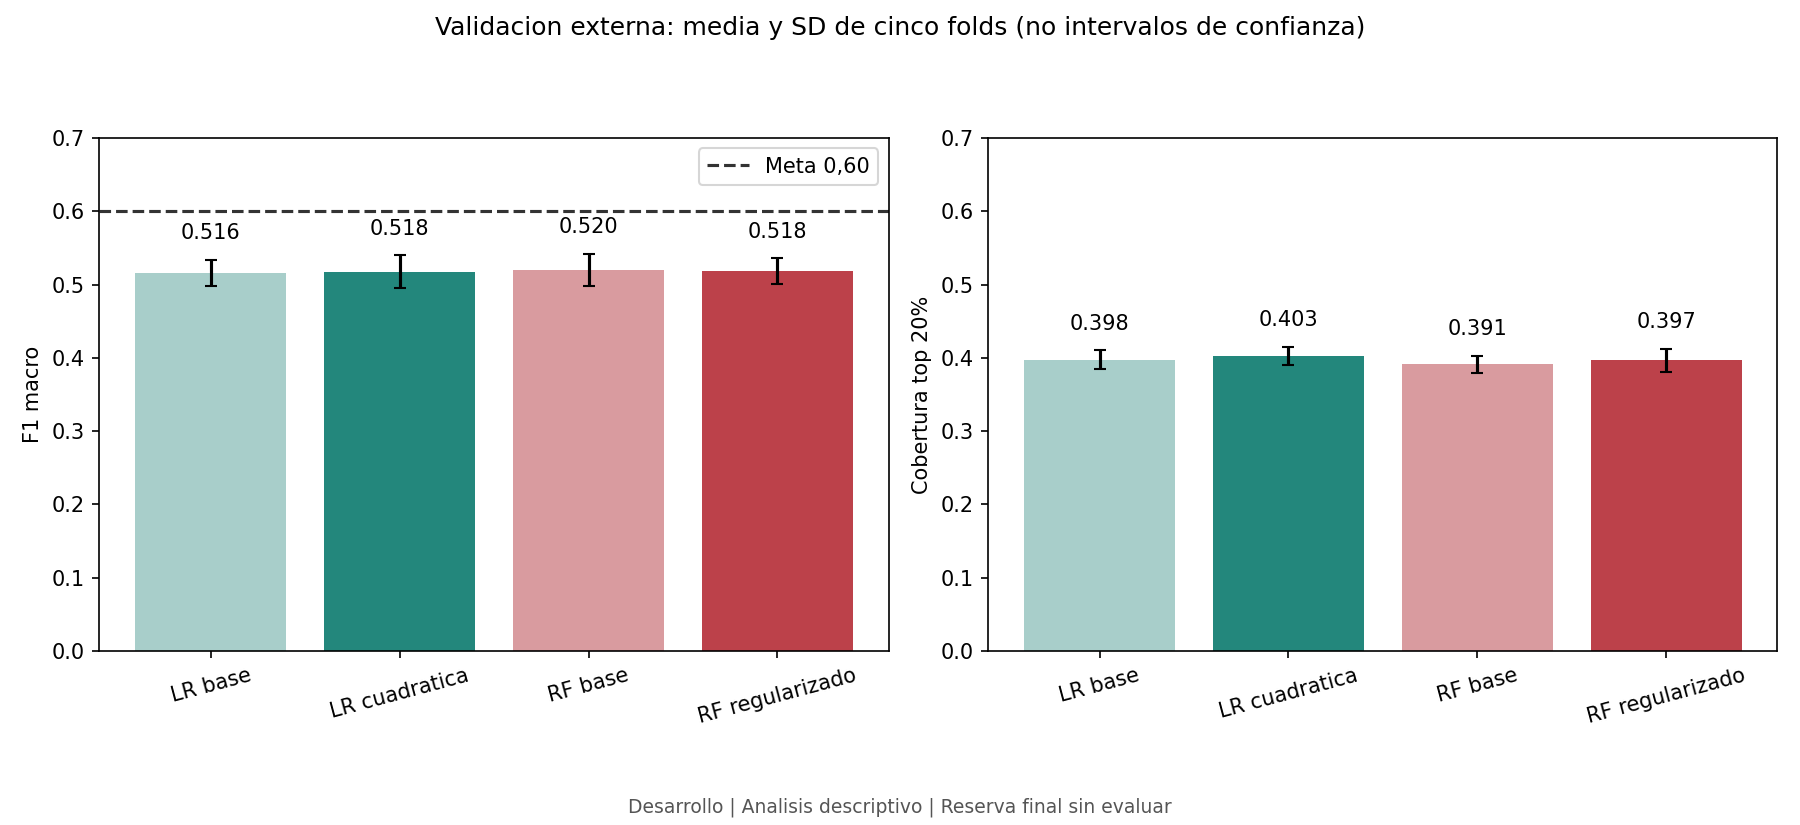

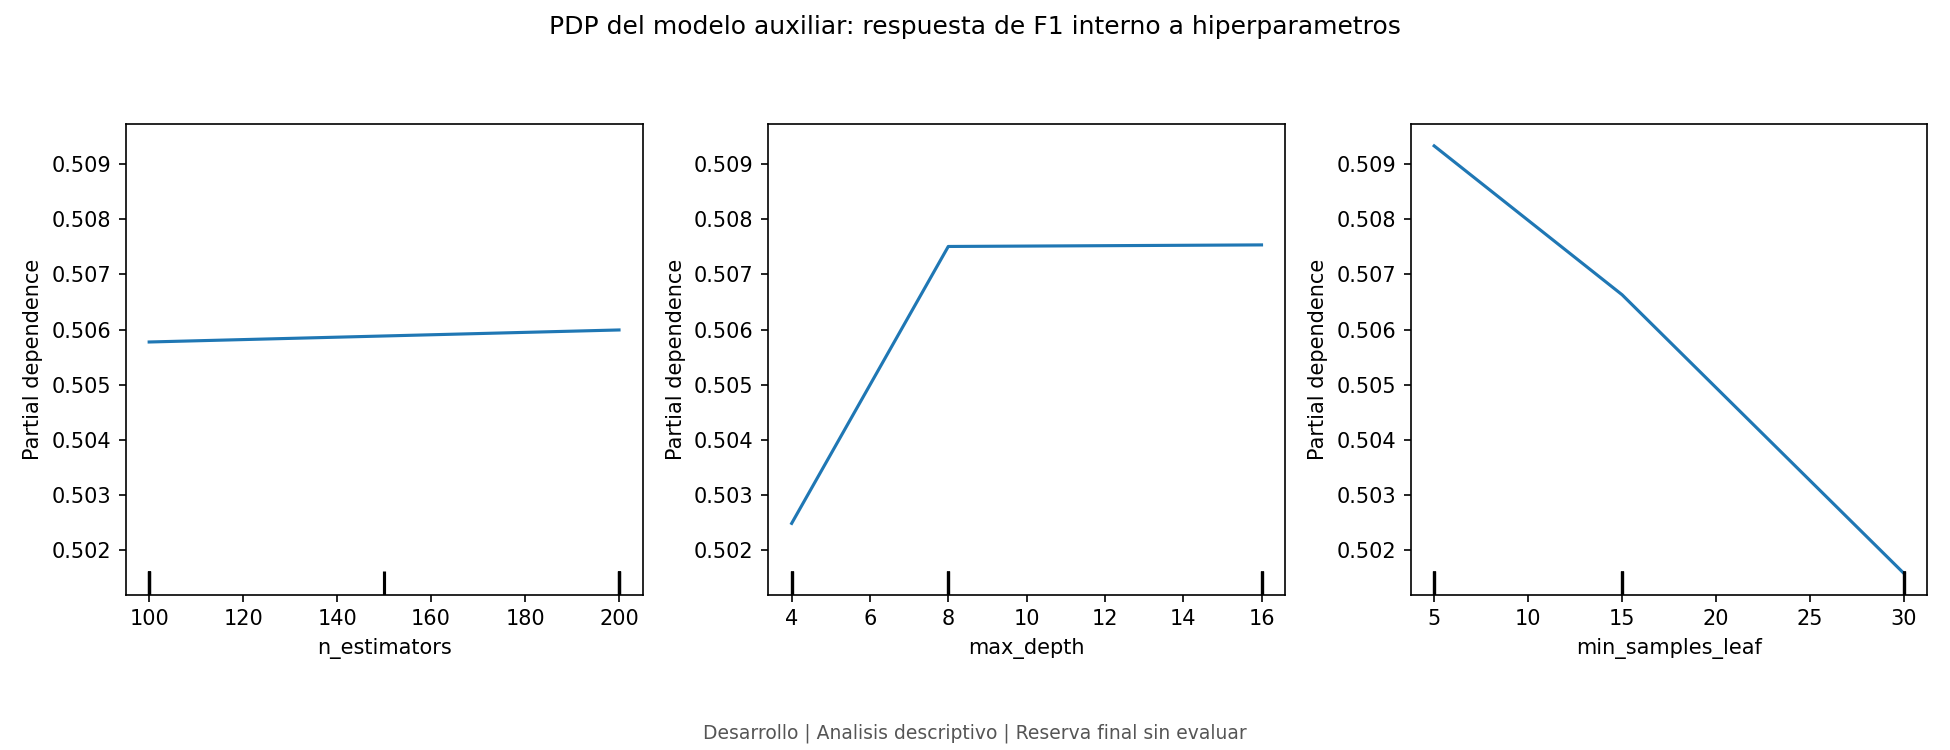

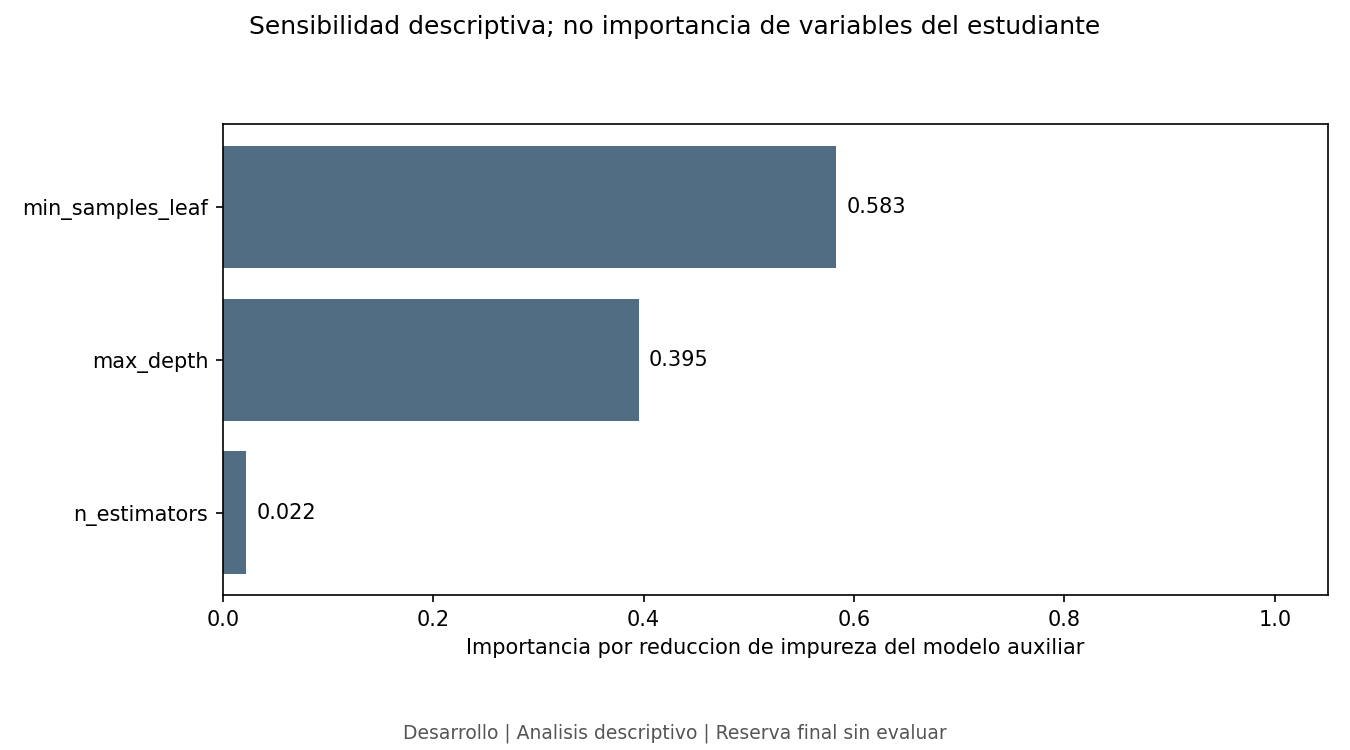

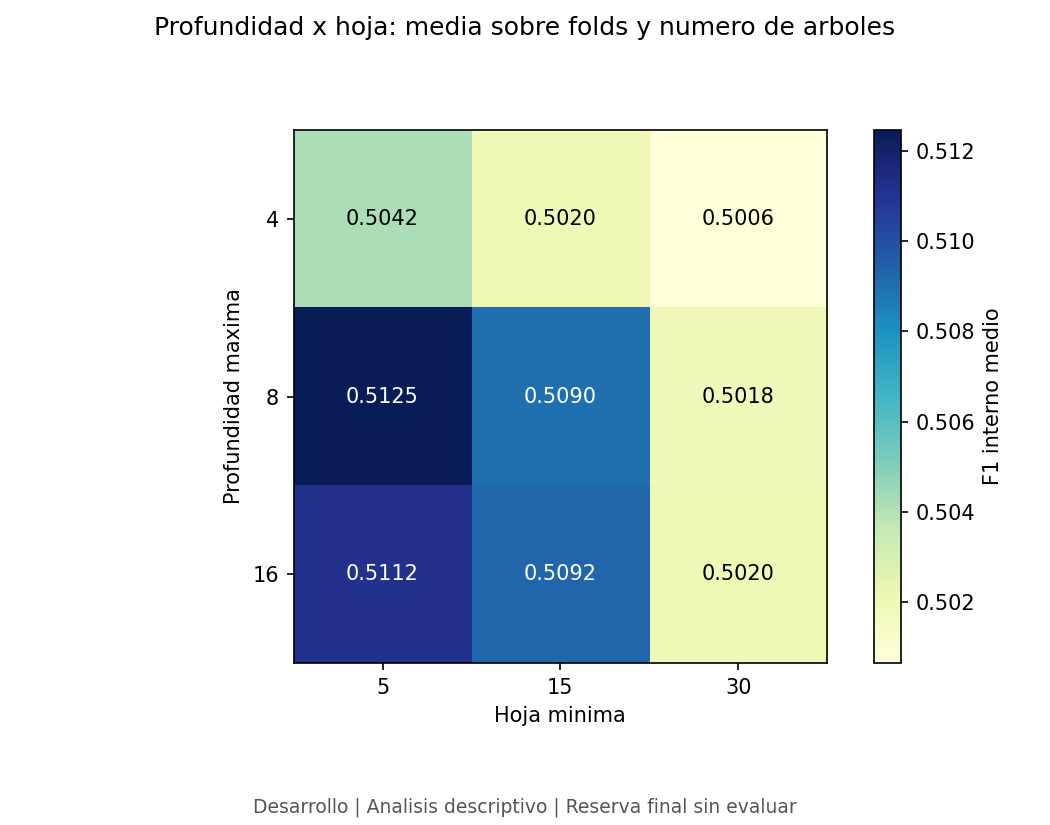

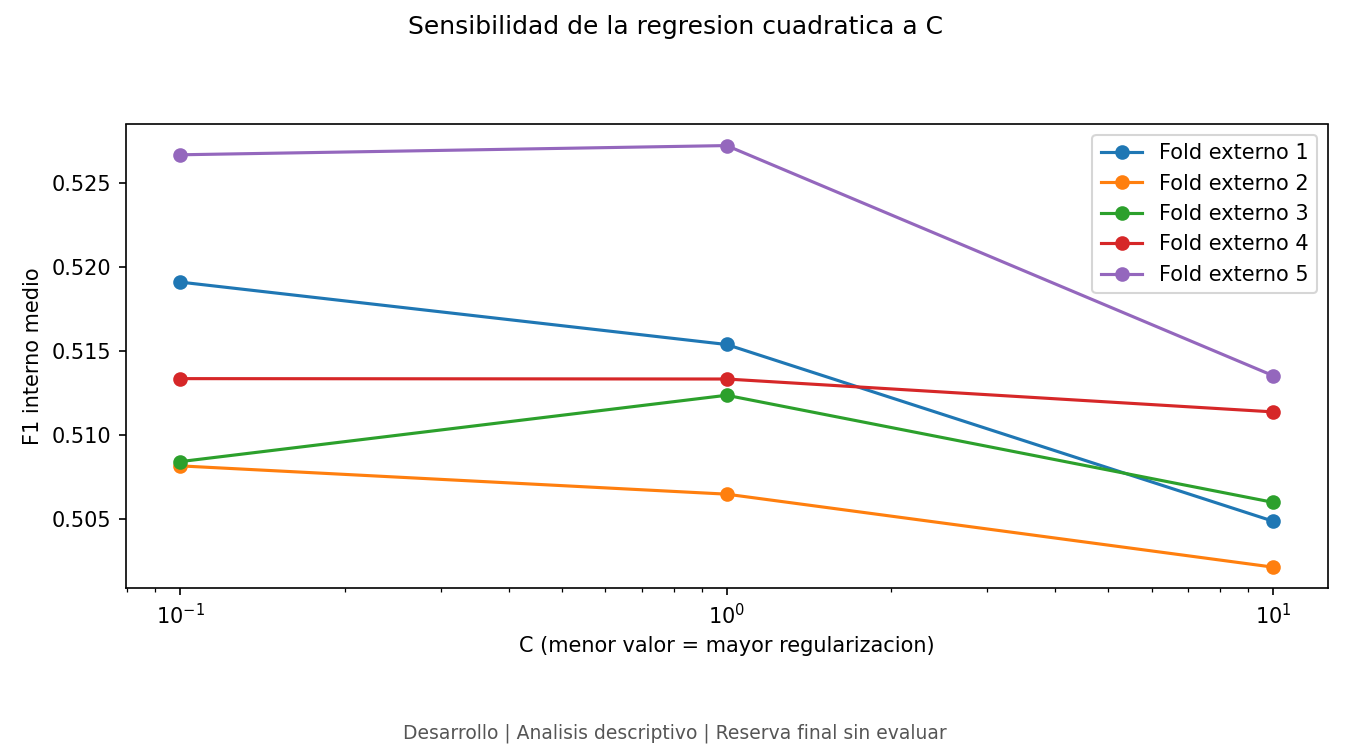

In [4]:
evidence = optimization_report.run()
display(pd.DataFrame(evidence['comparisons']).T[['baseline', 'delta_f1', 'delta_coverage', 'gap_before', 'gap_after']])
for name in optimization_report.FIGURES:
    display(Image(filename=str(ROOT / 'results/figures' / name)))

## Interpretacion y limites

RF reduce la brecha de 0,26061 a 0,09892, pero su F1 baja de 0,51996 a 0,51792. LR cuadratica pasa de 0,51584 a 0,51777: diferencia pequena, no mejora concluyente. Ambas aumentan cobertura alrededor de 0,53 puntos porcentuales. La meta F1 de 0,60 sigue sin alcanzarse.

PDP e importancias describen un modelo auxiliar ajustado a 18 puntos de busqueda interna; no explican abandono individual ni causalidad. R2 sobre esos mismos puntos mide fidelidad, no generalizacion. El mapa profundidad-hoja muestra combinaciones, no una prueba formal de interaccion. Los folds comparten entrenamiento.

No se ampliaron rangos tras observar resultados externos. Quedan pendientes estres, auditoria por subgrupos, calibracion, eleccion definitiva y prueba final. No hay modelo definitivo guardado. Protocolo, advertencias y resultados por fold se conservan en JSON/JSONL y docs/optimizacion.md.